# StreamWave Subscriber Churn Analysis

StreamWave is an OTT streaming platform facing subscriber churn and below-benchmark customer lifetime value. This analysis establishes a data-driven baseline for behavioral and pricing-related differences between churned and retained subscribers.

The project uses subscriber profiles and viewing sessions. The data dictionary and full project context are in `dataset/business_context.txt`.

## Minimal project structure

```text
MLS2/
├── EDA.ipynb
├── dataset/          # source CSV files and business context
├── outputs/          # generated analysis artifacts
├── pyproject.toml    # project dependencies for uv
└── uv.lock           # locked dependency versions
```

In [19]:
from pathlib import Path
import pandas as pd

# Find dataset/ relative to the project directory, regardless of the kernel working directory.
project_dir = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / 'dataset' / 'subscribers.csv').is_file()
)
data_dir = project_dir / 'dataset'
subscribers_raw = pd.read_csv(data_dir / 'subscribers.csv')
watch_history_raw = pd.read_csv(data_dir / 'watch_history.csv')

# Confirm that both raw dataframes loaded.
print(f'subscribers_raw: {subscribers_raw.shape[0]:,} rows x {subscribers_raw.shape[1]} columns')
print(f'watch_history_raw: {watch_history_raw.shape[0]:,} rows x {watch_history_raw.shape[1]} columns')

subscribers_raw: 10,000 rows x 15 columns
watch_history_raw: 306,935 rows x 11 columns


## Raw data quality audit

Audit each raw dataframe independently. The printed report is saved to `outputs/raw_data_quality_report.txt`.

In [20]:
from contextlib import redirect_stdout
from io import StringIO

raw_dataframes = {
    'subscribers_raw': subscribers_raw,
    'watch_history_raw': watch_history_raw,
}

report_buffer = StringIO()
with redirect_stdout(report_buffer):
    for name, df in raw_dataframes.items():
        print(f"--- Data Quality Audit: {name} ---")
        print(f"Rows: {df.shape[0]:,}")
        print(f"Columns: {df.shape[1]:,}")
        print("\nData types:")
        print(df.dtypes.to_string())

        missing_counts = df.isna().sum()
        missing_summary = pd.DataFrame({
            'missing_count': missing_counts,
            'missing_percent': (missing_counts / len(df) * 100).round(3),
        })
        print("\nMissing values by column:")
        print(missing_summary.to_string())
        print(f"\nTotal missing cells: {int(missing_counts.sum()):,}")
        print(f"Duplicate rows: {int(df.duplicated().sum()):,}")
        print()

report_path = project_dir / 'outputs' / 'raw_data_quality_report.txt'
report_path.parent.mkdir(parents=True, exist_ok=True)
report_text = report_buffer.getvalue()
print(report_text, end="")
report_path.write_text(report_text, encoding='utf-8')
print(f"Saved report to {report_path}")

--- Data Quality Audit: subscribers_raw ---
Rows: 10,000
Columns: 15

Data types:
subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub                 int64

Missing values by column:
                     missing_count  missing_percent
subscriber_id                    0             0.00
account_id                       0             0.00
age                            279             2.79
gender                         449             4.49
region                           0             0.00
country                          0             0.00
signup_date                      0             0.00
current_pl

## Prepare data for EDA

Summarize session-level watch history to one mean engagement score per subscriber, left-merge that summary onto the subscriber records, then parse the date fields in the merged dataframe.

In [21]:
# Aggregate session-level engagement to one mean score per subscriber.
subscriber_engagement = (
    watch_history_raw.groupby('subscriber_id', as_index=False)['engagement_score']
    .mean()
)

# Keep every subscriber and attach their engagement score when available.
merged_df = subscribers_raw.merge(
    subscriber_engagement,
    on='subscriber_id',
    how='left',
    validate='one_to_one'
)

# Parse the date columns in the merged subscriber-level dataframe.
date_columns = ['signup_date', 'churn_date']
for column in date_columns:
    merged_df[column] = pd.to_datetime(merged_df[column], errors='coerce')

print(f'merged_df: {merged_df.shape[0]:,} rows x {merged_df.shape[1]} columns')
print('Parsed date dtypes:')
print(merged_df[date_columns].dtypes.to_string())
print(f"Subscribers with no watch history engagement score: {merged_df['engagement_score'].isna().sum():,}")

merged_df: 10,000 rows x 16 columns
Parsed date dtypes:
signup_date    datetime64[ns]
churn_date     datetime64[ns]
Subscribers with no watch history engagement score: 135


### Subscriber count by acquisition channel

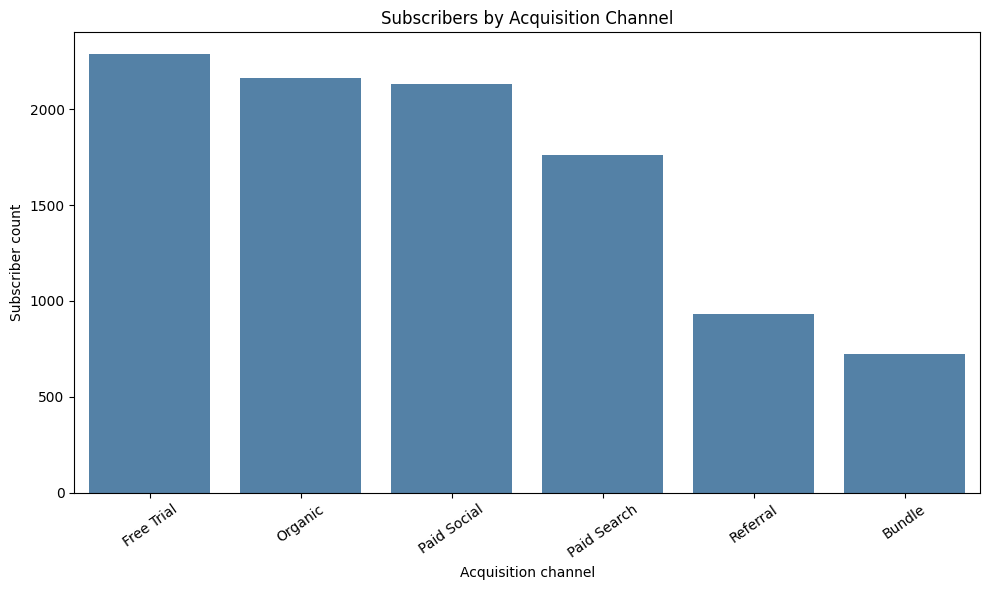

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/subscriber_count_by_channel.png


In [22]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

channel_counts = merged_df['signup_channel'].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=channel_counts.index, y=channel_counts.values, ax=ax, color="steelblue")
ax.set(title='Subscribers by Acquisition Channel', xlabel='Acquisition channel', ylabel='Subscriber count')
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()

figure_path = project_dir / 'outputs' / 'figures' / 'subscriber_count_by_channel.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** Free Trial is the largest acquisition channel by subscriber count, while Bundle is the smallest. The chart compares channel volume; it does not show retention or churn rates.

### Subscription tier, engagement, and subscriber tenure distributions

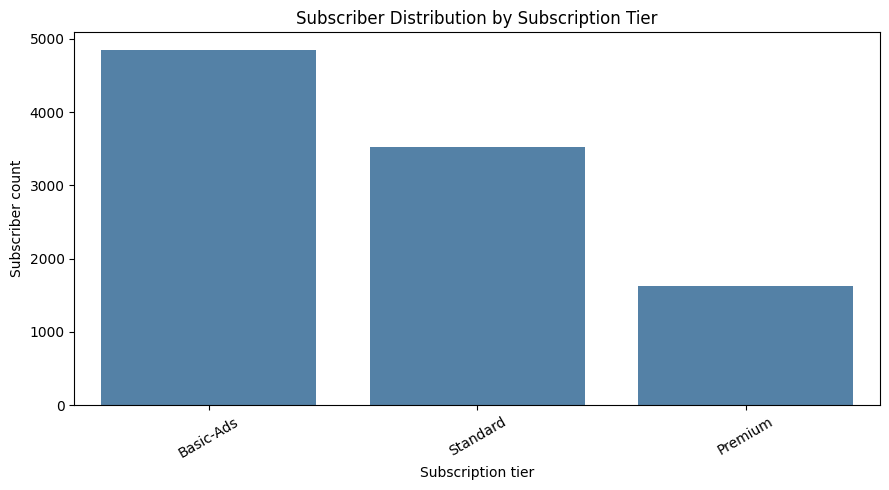

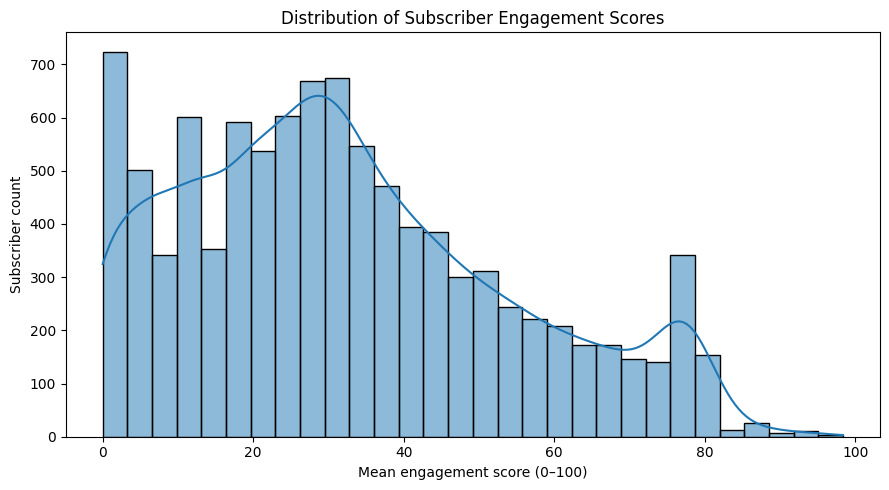

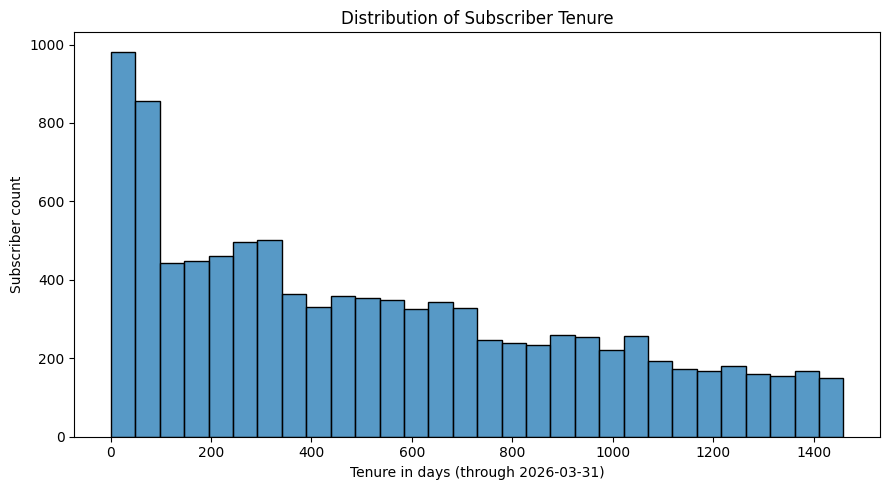

Saved subscription_tier_distribution.png, engagement_distribution.png, and subscriber_tenure_distribution.png to /home/dmedragh/PGP-AIML/MLS2/outputs/figures


In [23]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

figures_dir = project_dir / 'outputs' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

# Subscription tier distribution
plan_counts = merged_df['current_plan'].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=plan_counts.index, y=plan_counts.values, color="steelblue", ax=ax)
ax.set(title='Subscriber Distribution by Subscription Tier', xlabel='Subscription tier', ylabel='Subscriber count')
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(figures_dir / "subscription_tier_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Engagement score distribution. Missing values mean no matching watch-history activity.
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=merged_df, x="engagement_score", bins=30, kde=True, ax=ax)
ax.set(title='Distribution of Subscriber Engagement Scores', xlabel='Mean engagement score (0–100)', ylabel='Subscriber count')
fig.tight_layout()
fig.savefig(figures_dir / "engagement_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Define tenure as days from signup to the latest session date in the raw watch history.
analysis_end_date = pd.to_datetime(watch_history_raw['session_date'], errors='coerce').max()
merged_df["tenure_days"] = (analysis_end_date - merged_df["signup_date"]).dt.days
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=merged_df, x="tenure_days", bins=30, ax=ax)
ax.set(title='Distribution of Subscriber Tenure', xlabel=f'Tenure in days (through {analysis_end_date:%Y-%m-%d})', ylabel='Subscriber count')
fig.tight_layout()
fig.savefig(figures_dir / "subscriber_tenure_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved subscription_tier_distribution.png, engagement_distribution.png, and subscriber_tenure_distribution.png to", figures_dir)

**Observations:** Basic-Ads is the most common subscription tier, while Bundle is the least common. Engagement scores are concentrated in the lower to middle range, with fewer highly engaged subscribers; subscribers without watch sessions have no engagement score and are omitted from that histogram. Tenure spans a broad range, with signup dates measured through the latest recorded session date.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

merged_df['churn_label'] = merged_df['churn_status'].map({0: 'Retained', 1: 'Churned'})

### Engagement by acquisition channel

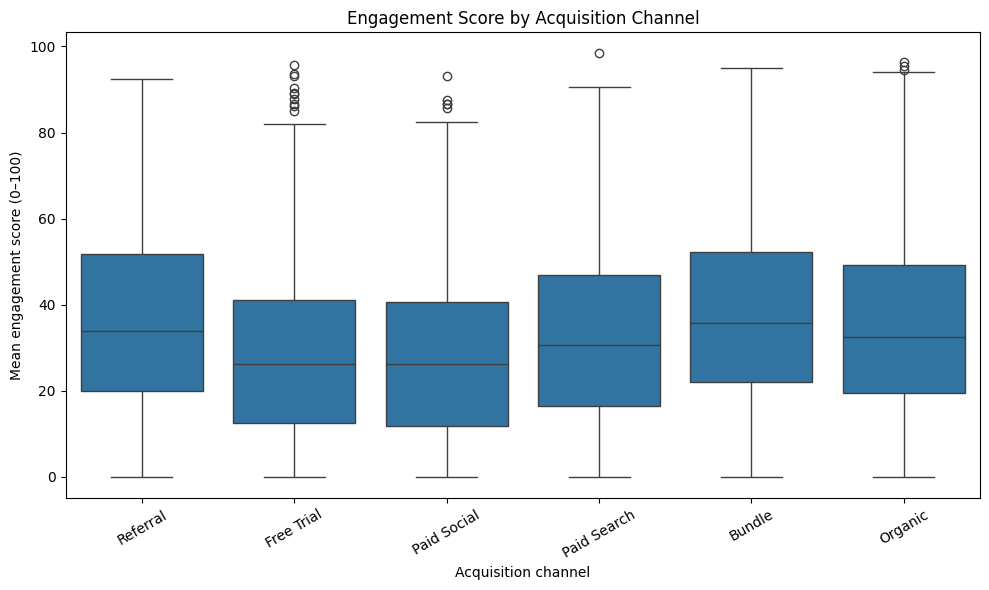

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/engagement_by_acquisition_channel.png


In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=merged_df, x='signup_channel', y='engagement_score', ax=ax)
ax.set(title='Engagement Score by Acquisition Channel', xlabel='Acquisition channel', ylabel='Mean engagement score (0–100)')
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
figure_path = project_dir / 'outputs' / 'figures' / 'engagement_by_acquisition_channel.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** Referral and Bundle subscribers have higher median engagement scores than the larger Free Trial and Paid Social groups. The box plots show the spread and outliers within each channel.

### Engagement by subscription plan

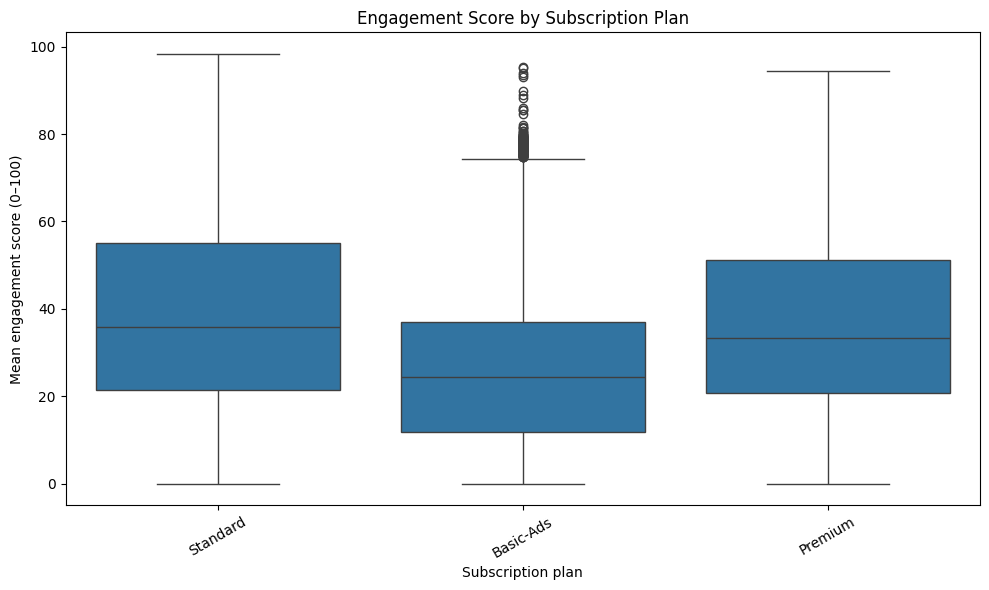

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/engagement_by_subscription_plan.png


In [26]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=merged_df, x='current_plan', y='engagement_score', ax=ax)
ax.set(title='Engagement Score by Subscription Plan', xlabel='Subscription plan', ylabel='Mean engagement score (0–100)')
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
figure_path = project_dir / 'outputs' / 'figures' / 'engagement_by_subscription_plan.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** Standard has the highest median engagement, with Premium slightly lower. Engagement distributions overlap across plans, so plan tier alone does not determine engagement.

### Engagement by churn status

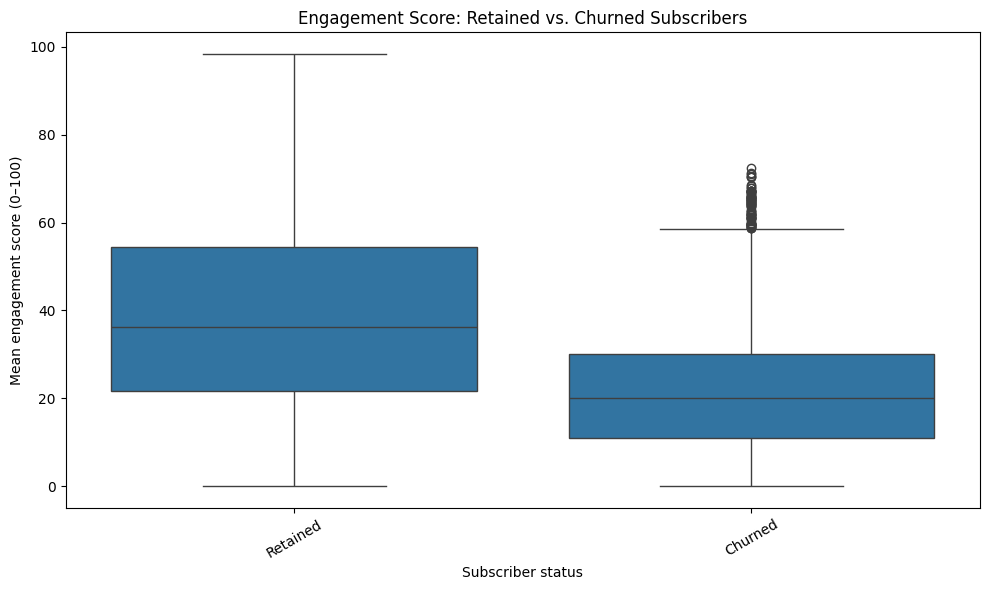

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/engagement_by_churn_status.png


In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=merged_df, x='churn_label', y='engagement_score', ax=ax)
ax.set(title='Engagement Score: Retained vs. Churned Subscribers', xlabel='Subscriber status', ylabel='Mean engagement score (0–100)')
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
figure_path = project_dir / 'outputs' / 'figures' / 'engagement_by_churn_status.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** Retained subscribers show higher engagement scores overall, while churned subscribers are concentrated at lower scores. Subscribers without recorded viewing sessions have no engagement score and are excluded from this plot.

## Engagement tiers and churn heatmaps

In [28]:
# Divide available subscriber-level engagement scores into five equal-sized quantiles.
engagement_tier_labels = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']
merged_df['engagement_tier'] = pd.qcut(
    merged_df['engagement_score'],
    q=5,
    labels=engagement_tier_labels,
    duplicates="drop"
)

# Confirm the score ranges and subscriber counts for the resulting tiers.
print(merged_df.groupby('engagement_tier', observed=False)['engagement_score'].agg(['min', 'max', 'count']))

                       min        max  count
engagement_tier                             
Checked Out       0.000000  12.309278   1973
Slowing Down     12.313552  24.668223   1973
Casual           24.684159  34.596030   1973
Regular          34.634493  51.172603   1973
Obsessed         51.178350  98.360263   1973


### Does engagement change channel-level churn risk?

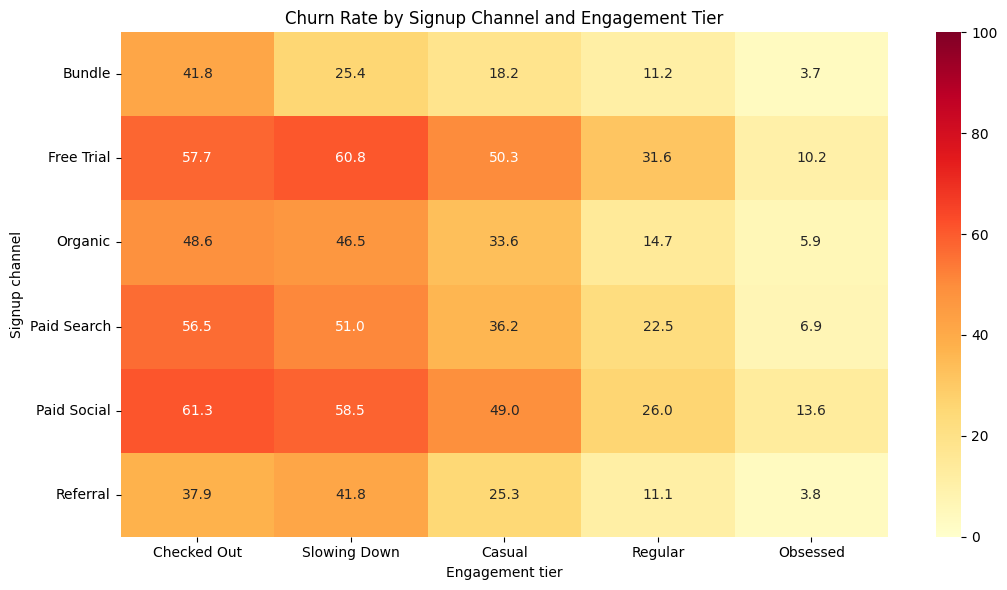

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/churn_by_channel_and_engagement_tier.png


In [29]:
# Churn rate (%) by signup channel and engagement tier.
channel_tier_churn = merged_df.pivot_table(
    index='signup_channel',
    columns='engagement_tier',
    values='churn_status',
    aggfunc="mean",
    observed=False
) * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(channel_tier_churn, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100, ax=ax)
ax.set(title='Churn Rate by Signup Channel and Engagement Tier', xlabel='Engagement tier', ylabel='Signup channel')
fig.tight_layout()
figure_path = project_dir / 'outputs' / 'figures' / 'churn_by_channel_and_engagement_tier.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** The Obsessed tier has the lowest churn rate in every signup channel, while Free Trial and Paid Social remain higher-risk channels even among highly engaged subscribers. Engagement is associated with lower churn, but channel differences persist.

### Does engagement reduce churn risk across subscription plans?

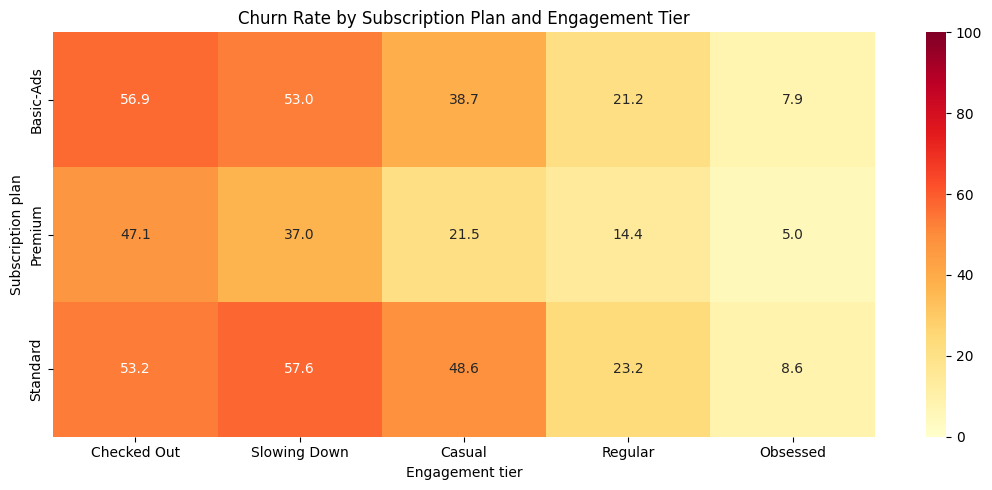

Saved figure to /home/dmedragh/PGP-AIML/MLS2/outputs/figures/churn_by_plan_and_engagement_tier.png


In [30]:
# Churn rate (%) by subscription plan and engagement tier.
plan_tier_churn = merged_df.pivot_table(
    index='current_plan',
    columns='engagement_tier',
    values='churn_status',
    aggfunc="mean",
    observed=False
) * 100

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(plan_tier_churn, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100, ax=ax)
ax.set(title='Churn Rate by Subscription Plan and Engagement Tier', xlabel='Engagement tier', ylabel='Subscription plan')
fig.tight_layout()
figure_path = project_dir / 'outputs' / 'figures' / 'churn_by_plan_and_engagement_tier.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {figure_path}")

**Observation:** The Obsessed tier has the lowest churn rate across all plans. Basic-Ads has relatively high churn at lower engagement, while Standard shows a local peak in the Slowing Down tier; engagement reduces risk but does not remove plan-level differences.

## Handle missing values

In [32]:
# A missing churn_date indicates an active subscriber, so keep those values null.
# A missing engagement_score indicates no recorded watch sessions; fill it with 0.
merged_df['engagement_score'] = merged_df['engagement_score'].fillna(0)

# Explicitly verify there are no missing engagement scores remaining.
engagement_null_count = int(merged_df['engagement_score'].isna().sum())
print(f"Null values remaining in engagement_score: {engagement_null_count}")
assert engagement_null_count == 0, "Missing engagement_score values remain."

# Leave churn_date unchanged; null values represent active subscribers.
print(f"Null churn_date values retained: {merged_df['churn_date'].isna().sum():,}")

Null values remaining in engagement_score: 0
Null churn_date values retained: 6,499


## Chi-square test: engagement tier and churn for Free Trial subscribers

In [33]:
from scipy.stats import chi2_contingency

# Ensure subscribers with no watch sessions (engagement_score = 0) receive an engagement tier.
free_trial = merged_df.loc[merged_df['signup_channel'].eq('Free Trial')].copy()
free_trial['engagement_tier'] = pd.qcut(
    free_trial['engagement_score'],
    q=5,
    labels=engagement_tier_labels,
    duplicates="drop"
)

# Build the 5 x 2 contingency table: engagement tiers by retained/churned status.
tier_order = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']
churn_order = [0, 1]
contingency_table = pd.crosstab(free_trial['engagement_tier'], free_trial['churn_status'])
contingency_table = contingency_table.reindex(index=tier_order, columns=churn_order, fill_value=0)
contingency_table.columns = ["Retained (0)", "Churned (1)"]
print("5 x 2 contingency table (Free Trial subscribers):")
print(contingency_table.to_string())

print("\nNull hypothesis (H0): Engagement tier and churn status are independent among Free Trial subscribers.")
print("Alternative hypothesis (H1): Engagement tier and churn status are dependent among Free Trial subscribers.")

chi2_stat, p_value, degrees_of_freedom, expected = chi2_contingency(contingency_table)
alpha = 0.05
print(f"\nChi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6g}")

if p_value < alpha:
    print(f"Conclusion (alpha = {alpha}): Reject H0. There is statistically significant evidence of a dependence between engagement tier and churn status for Free Trial subscribers.")
else:
    print(f"Conclusion (alpha = {alpha}): Accept H0 (fail to reject). There is insufficient evidence of a dependence between engagement tier and churn status for Free Trial subscribers.")

5 x 2 contingency table (Free Trial subscribers):
                 Retained (0)  Churned (1)
engagement_tier                           
Checked Out               211          247
Slowing Down              171          286
Casual                    201          256
Regular                   277          180
Obsessed                  406           52

Null hypothesis (H0): Engagement tier and churn status are independent among Free Trial subscribers.
Alternative hypothesis (H1): Engagement tier and churn status are dependent among Free Trial subscribers.

Chi-square statistic: 309.9024
Degrees of freedom: 4
P-value: 7.91672e-66
Conclusion (alpha = 0.05): Reject H0. There is statistically significant evidence of a dependence between engagement tier and churn status for Free Trial subscribers.
